In [1]:
from subprocess import run
import pandas as pd
import os
from nilearn import datasets,image, surface, plotting
import nibabel as nib
import numpy as np
import plotly.io as pio  # Import plotly.io for exporting images
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import warnings
from scipy.stats import norm


In [26]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge

def plot_circle_with_filled_sectors(flags):
    # Create a figure and axis
    fig, ax = plt.subplots(subplot_kw={'aspect': 'equal'})
    
    angle_off = 45*2
    # Draw the circle
    circle = plt.Circle((0.5, 0.5), 0.5, color='black', fill=False)
    ax.add_artist(circle)
    
    # Divide the circle into 8 equal sectors
    angles = np.linspace(0, 2 * np.pi, 9)
    
    # Iterate over all sectors to draw borders
    for i in range(1, 9):
        # Calculate the start and end angles for the sector
        start_angle = np.degrees(angles[i - 1])+angle_off
        end_angle = np.degrees(angles[i])+angle_off
        
        # Draw the sector with a black border
        wedge = Wedge((0.5, 0.5), 0.5, start_angle, end_angle, facecolor='none', edgecolor='black', linewidth=4)
        ax.add_patch(wedge)
    
    # Iterate over the flags to fill sectors with color
    for flag in flags.split():
        sector = int(flag[:-1])  # Extract sector number
        color = 'red' if flag[-1] == '+' else 'blue'  # Determine color
        
        # Calculate the start and end angles for the sector
        start_angle = np.degrees(angles[sector - 1])+angle_off
        end_angle = np.degrees(angles[sector])+angle_off
        
        # Draw the sector with color and black border
        wedge = Wedge((0.5, 0.5), 0.5, start_angle, end_angle, facecolor=color, edgecolor='black', linewidth=4,alpha=0.7)
        ax.add_patch(wedge)
    
    # Add piece index at the center of each sector
    for i in range(1, 9):
        # Calculate the midpoint angle of the sector
        mid_angle = np.degrees((angles[i - 1] + angles[i]) / 2)+angle_off
        
        # Convert the midpoint angle to radians for calculation
        mid_angle_rad = np.radians(mid_angle)
        
        # Calculate the position for the text (slightly inside the circle)
        text_x = 0.5 + 0.3 * np.cos(mid_angle_rad)  # 0.3 is the offset from the center
        text_y = 0.5 + 0.3 * np.sin(mid_angle_rad)
        
        # Add the text
        ax.text(text_x, text_y, str(i), ha='center', va='center', fontsize=60, color='black')
    
    # Set limits and remove axes
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')
    
    # Show the plot
    plt.show()



In [2]:
Dir_github = '/work/desai-lab/xuanyang/Project/Semantic/analysis/FactorAnalysis/github/FactorAnalysis_fMRI/scripts/'
Dir_mask = os.path.join(Dir_github,'fMRI','masks')

file_atlas = os.path.join(Dir_mask,'rs_HCPex.nii.gz')
img_atlas = image.load_img(file_atlas)
data_atlas = img_atlas.get_fdata()

file_mask = '/work/desai-lab/xuanyang/Project/Semantic/analysis/FactorAnalysis/github/FactorAnalysis_fMRI/scripts/fMRI/masks/rs_mask_GM_33.nii.gz'
img_mask = image.load_img(file_mask)
data_mask = img_mask.get_fdata()

data_atlas[data_mask==0] = 0

In [3]:
Dir_working = '/work/desai-lab/xuanyang/Project/Semantic/analysis/ParametricModulation/Nastase/allstories/FactorAnalysis'
Nvar = 113
NFA = 8
flag_model = f'Nvar{Nvar}NFA{NFA}_LPAC_multipleReg'
atlas_name = 'HCPex'
folder = 'nonthreshold'

Dir_model = os.path.join(Dir_working,'models',flag_model,f'FA{NFA}_{atlas_name}')
Dir_results = os.path.join(Dir_model,'results')
Dir_results_1st = os.path.join(Dir_results,'firstlevel')
Dir_results_2nd = os.path.join(Dir_results,'secondlevel')


In [4]:
p_value = 0.005
z_thresh = norm.ppf(1 - p_value)  # One-tailed (upper tail)
z_thresh

2.5758293035489004

In [5]:
df_results = []
for iFA in range(1,NFA+1):
        
    file_FA = os.path.join(Dir_results_2nd,folder,f"FA{iFA}+tlrc.BRIK.gz")
    
    if '.nii' in file_FA:
        img_FA = image.load_img(file_FA)
    else:
        img_FA = image.index_img(file_FA, 1) 
    
    data_FA = img_FA.get_fdata()
    data_threshold = data_FA.copy()
    data_threshold[np.abs(data_threshold)<=z_thresh] = 0
    if iFA == 7:
        data_threshold = data_threshold*-1
    # data_output = np.zeros(data_FA.shape)
    
    
    for i,roi in enumerate(np.unique(data_atlas)):
        
        # data_output[(data_atlas==roi)&(data_mask==1)] = data_FA[(data_atlas==roi)&(data_mask==1)].mean()
        roi_values = data_threshold[(data_atlas==roi)&(data_mask==1)]
        sig = 1 if roi_values[roi_values!=0].shape[0]>0 else 0
        label = ''
        if roi_values[0]>0:
            
            label = '+'
        elif roi_values[0]<0:
            label = '-'
        
        df_tmp = pd.DataFrame({'iFA':iFA,'ROI_idx':roi,'significant':sig,'alpha':p_value,'label':label},index=[0])
        df_results.append(df_tmp)
df_results = pd.concat(df_results,ignore_index=True)
df_results

,iFA,ROI_idx,significant,alpha,label
0,1,0.0,0,0.005,
1,1,1.0,0,0.005,
2,1,2.0,0,0.005,
3,1,3.0,0,0.005,
4,1,4.0,0,0.005,
...,...,...,...,...,...
3243,8,417.0,0,0.005,
3244,8,420.0,1,0.005,+
3245,8,424.0,0,0.005,
3246,8,425.0,0,0.005,


In [32]:
df_target = df_results.loc[df_results['ROI_idx']==277].copy()
# ' '.join(df_target.loc[df_target['label']!='','label'])
df_target = df_target.loc[df_target['label']!='']
flag = ' '.join(df_target['iFA'].astype(str)+df_target['label'])
print(flag)
df_results.loc[df_results['ROI_idx']==277]

1+ 2- 3- 4+ 6+ 7+ 8-


,iFA,ROI_idx,significant,alpha,label
277,1,277.0,1,0.005,+
683,2,277.0,1,0.005,-
1089,3,277.0,1,0.005,-
1495,4,277.0,1,0.005,+
1901,5,277.0,0,0.005,
2307,6,277.0,1,0.005,+
2713,7,277.0,1,0.005,+
3119,8,277.0,1,0.005,-


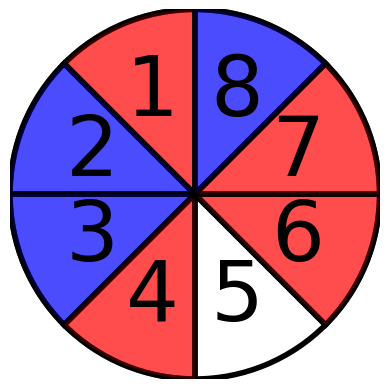

In [31]:
# Example usage
plot_circle_with_filled_sectors(flag)

In [29]:
df_atlas.loc[df_atlas['#No.']==241]

,#No.,Label,Name:,R,G,B
241,241,Auditory_5_Complex_R,192,183,155,0


In [35]:
def plot_surface(img,file_output,hemi,view,):
    if hemi == 'R':
        mesh = surface.load_surf_mesh(fsaverage.pial_right)
        bg_map = fsaverage.sulc_right
        hemi = 'right'
    else:
        mesh = surface.load_surf_mesh(fsaverage.pial_left)
        bg_map = fsaverage.sulc_left
        hemi = 'left'
        
    stat_map = surface.vol_to_surf(img, mesh)
    stat_map[stat_map>0.01] = 1
    
    th=0.2
#     if stat_map[stat_map!=0].shape[0] == 0:
#         th=0

    # Generate the Plotly figure
    fig = plotting.plot_surf(
        surf_mesh=mesh, surf_map=stat_map, bg_map=bg_map, hemi=hemi, view=view, 
        engine='plotly', cmap='coolwarm', symmetric_cmap=False, colorbar=False, 
    #     avg_method=None, 
        threshold=th, alpha=None, bg_on_data=False, #darkness=0.7, 
        vmin=-1, vmax=1, 
        cbar_vmin=None, cbar_vmax=None, 
        cbar_tick_format='auto', title=None, title_font_size=18, output_file=None, axes=None, figure=None)

    pio.write_image(fig.figure, file_output, format="jpg")

def compile_plots(img,Dir_output,title):
    
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 8),gridspec_kw={'height_ratios': [2, 1.5,1.5]})
    axes_flat = axes.flatten()

    for idx, ax in enumerate(axes_flat):
        hemi,view = df_views.loc[idx]

        file_output = os.path.join(Dir_output,f'tmp_{hemi}_{view}.jpg')
        plot_surface(img,file_output,hemi = hemi,view=view)

        img_jpg = mpimg.imread(file_output)
        if (hemi=='L') & (view == 'ventral'):
            img_jpg = np.flipud(img_jpg)
            img_jpg = np.fliplr(img_jpg)
        ax.imshow(img_jpg)
        ax.set_xticks([])  
        ax.set_yticks([])  
        ax.set_xlabel('')  
        ax.set_ylabel('')  
        ax.axis('off')  
    plt.suptitle(title)
    plt.tight_layout()
#     plt.show()
    plt.close()
#     file_output = filename.replace('img','fig').replace('.nii','.jpg')
    file_output = f"fig_conjunction_{title}.jpg"
    fig.savefig(os.path.join(Dir_output,file_output))

# Conjunction

In [9]:
df_views = []
for view in ['lateral','medial','ventral']:
    for hemi in ['L','R']:
    
        df_views.append(pd.DataFrame({'hemi':hemi,'view':view},index=[0]))
df_views = pd.concat(df_views,ignore_index=True)


In [10]:
df_atlas = pd.read_csv('/work/xy6/templates/HCPex_v1.1/HCPex_LookUpTable.txt',sep='\t')
df_atlas

,#No.,Label,Name:,R,G,B
0,0,Unknown,0,0,0,0
1,1,Primary_Visual_Cortex_L,208,216,117,0
2,2,Second_Visual_Area_L,231,50,224,0
3,3,Third_Visual_Area_L,33,58,133,0
4,4,Fourth_Visual_Area_L,233,44,241,0
...,...,...,...,...,...,...
422,422,Substantia_nigra_pars_reticulata_R,150,68,124,0
423,423,Ventral_tegmenta_area_R,53,40,216,0
424,424,Mammillary_bodies_R,77,72,54,0
425,425,Septal_nucleus_R,121,113,141,0


In [36]:
df_results_wide = df_results.pivot(index='ROI_idx',columns=['iFA'],values='significant')
List_FAs = [2,3,4,6,7,8]
overlap = ''.join([str(x) for x in List_FAs])
vector = df_results_wide[List_FAs].agg(lambda row: row.all(), axis=1).astype(int)


data_output = np.zeros(data_atlas.shape)
List_survive = vector[vector==1].index.to_list()
mask = np.isin(data_atlas, List_survive)
data_output[mask] = 1

if mask.any():
    # export
    warnings.filterwarnings("ignore", category=UserWarning)
    fsaverage = datasets.fetch_surf_fsaverage()
    
    Dir_output = os.path.join(Dir_results_2nd,'threshold_p005','conjunction','overlap')

    # binary
    new_img = image.new_img_like(img_atlas, data_output)
    output_path = os.path.join(Dir_output, f"FA{NFA}_{len(overlap)}FA{overlap}.nii.gz")
    new_img.to_filename(output_path)

    # surface
    title = f"{len(overlap)}FA{overlap}"
    compile_plots(new_img,Dir_output,title)
    
    # ROI labels
    df_atlas.loc[List_survive].to_csv(os.path.join(Dir_output,f"table_{title}.csv"),index=False)

    # MNI ROI labels
    data_output = data_atlas.copy()
    mask = np.isin(data_atlas, List_survive,invert=True)
    data_output[mask] = 0
    new_img = image.new_img_like(img_atlas, data_output)
    output_path = os.path.join(Dir_output, f"FA{NFA}_{len(overlap)}FA{overlap}_ROIlabels.nii.gz")
    new_img.to_filename(output_path)

# By ROI

In [66]:
df_conjunction = pd.DataFrame()
for i,roi in enumerate(df_results['ROI_idx'].unique()):
    df = df_results.loc[df_results['ROI_idx']==roi]
    
    values = df.loc[df['significant']==1,'iFA'].astype(str).values
    text = ''.join(values)
    if text != '':
        df_conjunction.loc[i,'ROI_idx'] = roi
        df_conjunction.loc[i,'conjunction'] = text
        df_conjunction.loc[i,'number'] = len(values)
df_conjunction.sort_values(['number'],ascending = False,inplace=True)
df_conjunction

,ROI_idx,conjunction,number
241,241.0,1234678,7.0
277,277.0,1234678,7.0
160,160.0,235678,6.0
244,244.0,234678,6.0
381,387.0,12367,5.0
...,...,...,...
191,191.0,5,1.0
192,192.0,7,1.0
193,193.0,6,1.0
196,196.0,6,1.0


# Plot

In [98]:
def plot_surface(img,file_output,hemi,view,):
    if hemi == 'R':
        mesh = surface.load_surf_mesh(fsaverage.pial_right)
        bg_map = fsaverage.sulc_right
        hemi = 'right'
    else:
        mesh = surface.load_surf_mesh(fsaverage.pial_left)
        bg_map = fsaverage.sulc_left
        hemi = 'left'
        
    stat_map = surface.vol_to_surf(img, mesh)
    stat_map[stat_map>0.01] = 1
    
    th=0.2
#     if stat_map[stat_map!=0].shape[0] == 0:
#         th=0

    # Generate the Plotly figure
    fig = plotting.plot_surf(
        surf_mesh=mesh, surf_map=stat_map, bg_map=bg_map, hemi=hemi, view=view, 
        engine='plotly', cmap='coolwarm', symmetric_cmap=False, colorbar=False, 
    #     avg_method=None, 
        threshold=th, alpha=None, bg_on_data=False, #darkness=0.7, 
        vmin=-1, vmax=1, 
        cbar_vmin=None, cbar_vmax=None, 
        cbar_tick_format='auto', title=None, title_font_size=18, output_file=None, axes=None, figure=None)

    pio.write_image(fig.figure, file_output, format="jpg")

def compile_plots(img,Dir_output,title):
    
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 8),gridspec_kw={'height_ratios': [2, 1.5,1.5]})
    axes_flat = axes.flatten()

    for idx, ax in enumerate(axes_flat):
        hemi,view = df_views.loc[idx]

        file_output = os.path.join(Dir_output,f'tmp_{hemi}_{view}.jpg')
        plot_surface(img,file_output,hemi = hemi,view=view)

        img_jpg = mpimg.imread(file_output)
        if (hemi=='L') & (view == 'ventral'):
            img_jpg = np.flipud(img_jpg)
            img_jpg = np.fliplr(img_jpg)
        ax.imshow(img_jpg)
        ax.set_xticks([])  
        ax.set_yticks([])  
        ax.set_xlabel('')  
        ax.set_ylabel('')  
        ax.axis('off')  
    plt.suptitle(title)
    plt.tight_layout()
#     plt.show()
    plt.close()
#     file_output = filename.replace('img','fig').replace('.nii','.jpg')
    file_output = f"fig_conjunction_{title}.jpg"
    fig.savefig(os.path.join(Dir_output,file_output))

In [100]:
# Suppress all user warnings
warnings.filterwarnings("ignore", category=UserWarning)
fsaverage = datasets.fetch_surf_fsaverage()

Dir_output = os.path.join(Dir_results_2nd,'threshold_p005','conjunction')

for overlap in df_conjunction.loc[df_conjunction['number']>=3]['conjunction'].unique():
    df_tmp = df_conjunction.loc[df_conjunction['conjunction']==overlap]
    data_output = np.zeros(data_atlas.shape)
    mask = np.isin(data_atlas, list(df_tmp['ROI_idx'].unique()))
    data_output[mask] = 1
    
     
    # export
    new_img = image.new_img_like(img_atlas, data_output)
    output_path = os.path.join(Dir_output, f"FA{NFA}_{len(overlap)}FA{overlap}.nii.gz")
    new_img.to_filename(output_path)
    title = f"{len(overlap)}FA{overlap}"
    compile_plots(new_img,Dir_output,title)

# all in one

In [104]:
# all over 3
df_tmp = df_conjunction.loc[df_conjunction['number']>=3]
data_output = data_atlas.copy()

mask = np.isin(data_atlas, list(df_tmp['ROI_idx'].unique()),invert=True)
data_output[mask] = 0
# export
new_img = image.new_img_like(img_atlas, data_output)
output_path = os.path.join(Dir_output, f"FA{NFA}_allover3.nii.gz")
new_img.to_filename(output_path)
title = f"FA{NFA}_allover3"
compile_plots(new_img,Dir_output,title)

In [105]:
# 2 
df_tmp = df_conjunction.loc[df_conjunction['number']==2]
data_output = data_atlas.copy()

mask = np.isin(data_atlas, list(df_tmp['ROI_idx'].unique()),invert=True)
data_output[mask] = 0
# export
new_img = image.new_img_like(img_atlas, data_output)
output_path = os.path.join(Dir_output, f"FA{NFA}_all2.nii.gz")
new_img.to_filename(output_path)
title = f"FA{NFA}_all2"
compile_plots(new_img,Dir_output,title)

In [121]:
# 
data_output = np.zeros(data_atlas.shape)
for number in df_conjunction['number'].unique():
    df_tmp = df_conjunction.loc[df_conjunction['number']==number]
    df_tmp = df_tmp.loc[df_tmp['ROI_idx']!=0]
    mask = np.isin(data_atlas, list(df_tmp['ROI_idx'].unique()))
    data_output[mask] = number

# export
new_img = image.new_img_like(img_atlas, data_output)
output_path = os.path.join(Dir_output, f"FA{NFA}_gradient.nii.gz")
new_img.to_filename(output_path)
title = f"FA{NFA}_gradient"
compile_plots(new_img,Dir_output,title)    

In [123]:
df_conjunction.loc[df_conjunction['number']==1]

,ROI_idx,conjunction,number
314,314.0,8,1.0
275,275.0,2,1.0
396,410.0,1,1.0
329,329.0,3,1.0
354,354.0,3,1.0
...,...,...,...
191,191.0,5,1.0
192,192.0,7,1.0
193,193.0,6,1.0
196,196.0,6,1.0


In [120]:
number = 4
df_tmp = df_conjunction.loc[df_conjunction['number']==number]
df_tmp = df_tmp.loc[df_tmp['ROI_idx']!=0]
df_tmp['ROI_idx'].unique()

array([ 93.,  88., 333., 264., 313., 155.,  61., 163., 167., 168., 217.,
       278., 240., 345., 263., 420.])